In [1]:
# Akshar Setu – Gujarati OCR Fine-Tuning

## Experiment 2: Tesseract LSTM Fine-Tuning

Objective:
Fine-tune the pretrained Gujarati Tesseract LSTM model
using a Gujarati printed line-image dataset.

Dataset:
- Training: 800 images
- Validation: 100 images
- Test: 100 images

Evaluation:
- CER
- WER
- Exact Match Accuracy

Baseline:
Gujarati Tesseract (`guj`)

Fine-tuned:
Custom Gujarati Tesseract (`guj_custom`)

SyntaxError: invalid syntax (3257283456.py, line 5)

In [2]:
import sys
import os

print("Python version:")
print(sys.version)

print("\nPython executable:")
print(sys.executable)

Python version:
3.13.0 (tags/v3.13.0:60403a5, Oct  7 2024, 09:38:07) [MSC v.1941 64 bit (AMD64)]

Python executable:
D:\code material 2.0\akshar-setu-v2\.venv\Scripts\python.exe


In [3]:
%pip install pandas numpy pillow matplotlib jiwer rapidfuzz tqdm

Note: you may need to restart the kernel to use updated packages.


D:\code material 2.0\akshar-setu-v2\.venv\Scripts\python.exe: No module named pip


In [3]:
import os
import re
import time
import subprocess
import unicodedata

import pandas as pd
import numpy as np

from PIL import Image
from pathlib import Path

import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from rapidfuzz.distance import Levenshtein
from jiwer import wer

D:\code material 2.0\akshar-setu-v2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
PROJECT_DIR = Path(r"D:\code material 2.0\akshar-setu-v2")

DATA_DIR = PROJECT_DIR / "data" / "tesseract"

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR   = DATA_DIR / "validation"
TEST_DIR  = DATA_DIR / "test"

print("Project:", PROJECT_DIR)
print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)

Project: D:\code material 2.0\akshar-setu-v2
Train: D:\code material 2.0\akshar-setu-v2\data\tesseract\train
Validation: D:\code material 2.0\akshar-setu-v2\data\tesseract\validation
Test: D:\code material 2.0\akshar-setu-v2\data\tesseract\test


In [5]:
for name, path in {
    "Train": TRAIN_DIR,
    "Validation": VAL_DIR,
    "Test": TEST_DIR
}.items():

    print(f"{name}:")
    print("  Exists:", path.exists())
    print("  Path:", path)
    print()

Train:
  Exists: True
  Path: D:\code material 2.0\akshar-setu-v2\data\tesseract\train

Validation:
  Exists: True
  Path: D:\code material 2.0\akshar-setu-v2\data\tesseract\validation

Test:
  Exists: True
  Path: D:\code material 2.0\akshar-setu-v2\data\tesseract\test



In [6]:
def dataset_statistics(folder):
    images = list(folder.glob("*.png"))
    labels = list(folder.glob("*.gt.txt"))

    image_stems = {x.stem for x in images}
    label_stems = {x.stem.replace(".gt", "") for x in labels}

    missing_labels = image_stems - label_stems
    missing_images = label_stems - image_stems

    return {
        "images": len(images),
        "labels": len(labels),
        "missing_labels": len(missing_labels),
        "missing_images": len(missing_images),
    }


stats = pd.DataFrame({
    "Train": dataset_statistics(TRAIN_DIR),
    "Validation": dataset_statistics(VAL_DIR),
    "Test": dataset_statistics(TEST_DIR)
}).T

stats

,images,labels,missing_labels,missing_images
Train,800,800,0,0
Validation,100,100,0,0
Test,100,100,0,0


In [7]:
sample_image = sorted(TRAIN_DIR.glob("*.png"))[0]

sample_gt = sample_image.with_suffix(".gt.txt")

print("Image:")
print(sample_image)

print("\nGround truth:")
print(sample_gt.read_text(encoding="utf-8"))

Image:
D:\code material 2.0\akshar-setu-v2\data\tesseract\train\train_000000.png

Ground truth:
સારવાર પછી પણ


D:\code material 2.0\akshar-setu-v2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 2744 (\N{GUJARATI LETTER SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\code material 2.0\akshar-setu-v2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 2736 (\N{GUJARATI LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\code material 2.0\akshar-setu-v2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 2741 (\N{GUJARATI LETTER VA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\code material 2.0\akshar-setu-v2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 2730 (\N{GUJARATI LETTER PA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\code material 2.0\akshar-setu-v2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 2715 (\N{GUJARATI LET

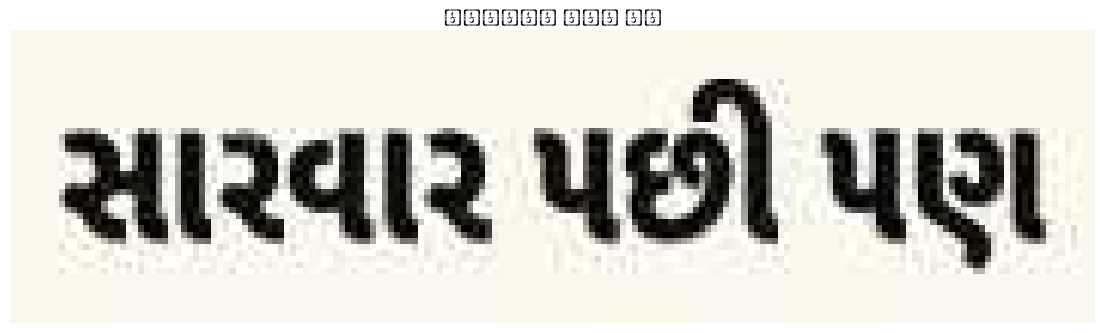

In [8]:
img = Image.open(sample_image)

plt.figure(figsize=(14, 4))
plt.imshow(img)
plt.axis("off")
plt.title(sample_gt.read_text(encoding="utf-8").strip())

plt.show()

In [9]:
def normalize_text(text):
    text = unicodedata.normalize("NFC", text)
    text = text.replace("\r\n", "\n")
    text = text.replace("\r", "\n")
    return text.strip()


def read_gt(path):
    return normalize_text(
        Path(path).read_text(encoding="utf-8")
    )

In [10]:
def check_unicode(folder):
    results = []

    for gt_file in folder.glob("*.gt.txt"):
        text = read_gt(gt_file)

        results.append({
            "file": gt_file.name,
            "characters": len(text),
            "words": len(text.split()),
            "empty": len(text) == 0
        })

    return pd.DataFrame(results)


train_info = check_unicode(TRAIN_DIR)

train_info.describe()

,characters,words
count,800.00000,800.000000
mean,23.49250,4.023750
std,14.67529,2.420849
min,2.00000,1.000000
25%,11.00000,2.000000
50%,20.00000,3.000000
75%,36.25000,6.000000
max,50.00000,12.000000


In [11]:
empty_labels = train_info[train_info["empty"]]

print("Empty labels:", len(empty_labels))

empty_labels.head()

Empty labels: 0


,file,characters,words,empty


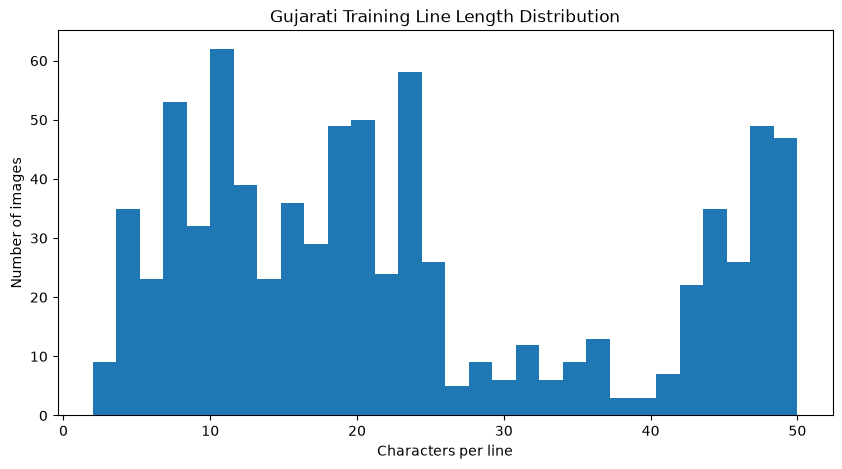

In [12]:
plt.figure(figsize=(10, 5))

plt.hist(
    train_info["characters"],
    bins=30
)

plt.xlabel("Characters per line")
plt.ylabel("Number of images")
plt.title("Gujarati Training Line Length Distribution")

plt.show()

In [13]:
dimensions = []

for image_file in TRAIN_DIR.glob("*.png"):
    with Image.open(image_file) as img:
        dimensions.append({
            "file": image_file.name,
            "width": img.width,
            "height": img.height
        })

dimensions_df = pd.DataFrame(dimensions)

dimensions_df.describe()

,width,height
count,800.000000,800.0
mean,283.190000,48.0
std,163.667476,0.0
min,32.000000,48.0
25%,155.000000,48.0
50%,241.500000,48.0
75%,392.250000,48.0
max,788.000000,48.0


In [14]:
result = subprocess.run(
    ["wsl", "tesseract", "--version"],
    capture_output=True,
    text=True
)

print(result.stdout)

tesseract 5.5.0
 leptonica-1.86.0
  libgif 5.2.2 : libjpeg 8d (libjpeg-turbo 2.1.5) : libpng 1.6.57 : libtiff 4.7.0 : zlib 1.3.1 : libwebp 1.5.0 : libopenjp2 2.5.4
 Found AVX2
 Found AVX
 Found FMA
 Found SSE4.1
 Found OpenMP 201511
 Found libarchive 3.8.5 zlib/1.3.1 liblzma/5.8.3 bz2lib/1.0.8 liblz4/1.10.0 libzstd/1.5.7 nettle/3.10 libb2/bundled libacl/2.3.2 libattr/2.3.2
 Found libcurl/8.18.0 OpenSSL/3.5.5 zlib/1.3.1 brotli/1.2.0 zstd/1.5.7 libidn2/2.3.8 libpsl/0.21.2 libssh2/1.11.1 nghttp2/1.68.0 librtmp/2.3 mit-krb5/1.22.1 OpenLDAP/2.6.10



In [15]:
result = subprocess.run(
    ["wsl", "tesseract", "--list-langs"],
    capture_output=True,
    text=True
)

print(result.stdout)

List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (4):
eng
guj
guj_custom
osd



In [20]:
def windows_to_wsl(path):
    path = Path(path).resolve()

    drive = path.drive[0].lower()
    relative = str(path).replace("\\", "/")[3:]

    return f"/mnt/{drive}/{relative}"


def tesseract_predict(image_path, model="guj"):

    wsl_image_path = windows_to_wsl(image_path)

    result = subprocess.run(
        [
            "wsl",
            "tesseract",
            wsl_image_path,
            "stdout",
            "-l",
            model
        ],
        capture_output=True,
        text=True,
        encoding="utf-8"
    )

    if result.returncode != 0:
        print("Tesseract ERROR:")
        print(result.stderr)

    return normalize_text(result.stdout)

In [21]:
image = sorted(TEST_DIR.glob("*.png"))[0]

print("Windows path:")
print(image)

print("\nWSL path:")
print(windows_to_wsl(image))

Windows path:
D:\code material 2.0\akshar-setu-v2\data\tesseract\test\test_000000.png

WSL path:
/mnt/d/code material 2.0/akshar-setu-v2/data/tesseract/test/test_000000.png


In [22]:
image = sorted(TEST_DIR.glob("*.png"))[0]

gt_file = image.with_suffix(".gt.txt")

ground_truth = read_gt(gt_file)

prediction = tesseract_predict(image, "guj")

print("GROUND TRUTH:")
print(ground_truth)

print("\nBASELINE PREDICTION:")
print(prediction)

GROUND TRUTH:
અસર પામે છે.

BASELINE PREDICTION:
અંસર પામે છે.


In [23]:
def evaluate_model(folder, model):

    results = []

    images = sorted(folder.glob("*.png"))

    for image in tqdm(images):

        gt_file = image.with_suffix(".gt.txt")

        if not gt_file.exists():
            continue

        ground_truth = read_gt(gt_file)

        start = time.time()

        prediction = tesseract_predict(
            image,
            model
        )

        inference_time = time.time() - start

        char_errors = Levenshtein.distance(
            ground_truth,
            prediction
        )

        cer = char_errors / max(len(ground_truth), 1)

        try:
            current_wer = wer(
                ground_truth,
                prediction
            )
        except:
            current_wer = 0

        results.append({
            "image": image.name,
            "ground_truth": ground_truth,
            "prediction": prediction,
            "CER": cer,
            "WER": current_wer,
            "inference_time": inference_time
        })

    return pd.DataFrame(results)

In [24]:
baseline_results = evaluate_model(
    TEST_DIR,
    "guj"
)

baseline_results.head()

100%|██████████| 100/100 [00:23<00:00,  4.28it/s]


,image,ground_truth,prediction,CER,WER,inference_time
0,test_000000.png,અસર પામે છે.,અંસર પામે છે.,0.083333,0.333333,3.644916
1,test_000001.png,હું પુનરાવર્તન કરવાની જરૂર છે,હું પુનરાવર્તન કરવાની જરૂર છે,0.000000,0.000000,0.209404
2,test_000002.png,કરો: - પ્રોટીન સામગ્રી: કૃમિ સારી માત્રામાં,કરો! - પ્રોટીન સામગ્રીઃ કુમિ સારો માત્રામાં,0.093023,0.571429,0.204704
3,test_000003.png,ફિલ્મથી વિડિઓ સુધી,ફિલ્મથી વિડિઓ સુધી,0.000000,0.000000,0.195502
4,test_000004.png,સાઇટ સાથે જોડે છે.,,1.000000,1.000000,0.166090


In [25]:
baseline_cer = (
    baseline_results["CER"].sum()
    * 0
)

total_errors = 0
total_characters = 0

for _, row in baseline_results.iterrows():

    gt = row["ground_truth"]
    pred = row["prediction"]

    total_errors += Levenshtein.distance(gt, pred)
    total_characters += len(gt)

baseline_cer = total_errors / max(total_characters, 1)

baseline_wer = baseline_results["WER"].mean()

print("========== BASELINE ==========")
print(f"Images: {len(baseline_results)}")
print(f"CER: {baseline_cer * 100:.2f}%")
print(f"Average WER: {baseline_wer * 100:.2f}%")

========== BASELINE ==========
Images: 100
CER: 19.90%
Average WER: 31.86%


In [26]:
result = subprocess.run(
    [
        "wsl",
        "bash",
        "-lc",
        "cd ~/tesstrain && pwd && ls"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

/home/janmejaywsl/tesstrain
LICENSE
Makefile
README.md
count_chars.py
data
evaluate.py
evaluate_baseline.py
generate_eval_train.py
generate_gt_from_box.py
generate_line_box.py
generate_line_syllable_box.py
generate_wordstr_box.py
normalize.py
ocr-env
ocrd-testset.zip
ocrd.plot_cer.png
plot_cer.py
plot_log.py
requirements.txt
shuffle.py
src
usr



In [27]:
cmd = r"""
cd ~/tesstrain

rm -rf data/guj_experiment2

mkdir -p data/guj_experiment2/train
mkdir -p data/guj_experiment2/validation
"""

subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    check=True
)

print("Directories created.")

Directories created.


In [28]:
train_wsl = "/mnt/d/code material 2.0/akshar-setu-v2/data/tesseract/train"
val_wsl = "/mnt/d/code material 2.0/akshar-setu-v2/data/tesseract/validation"

cmd = f"""
cd ~/tesstrain

cp "{train_wsl}"/* data/guj_experiment2/train/
cp "{val_wsl}"/* data/guj_experiment2/validation/
"""

subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    check=True
)

print("Training and validation data copied.")

Training and validation data copied.


In [29]:
cmd = r"""
cd ~/tesstrain

rm -rf data/guj-experiment2-ground-truth

mkdir -p data/guj-experiment2-ground-truth

cp data/guj_experiment2/train/* \
data/guj-experiment2-ground-truth/

"""

subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    check=True
)

print("Ground truth prepared.")

Ground truth prepared.


debugging


In [32]:
import subprocess

cmd = r"""
cd ~/tesstrain

echo "PNG files:"
find data/guj-experiment2-ground-truth -maxdepth 1 -name "*.png" | wc -l

echo "GT files:"
find data/guj-experiment2-ground-truth -maxdepth 1 -name "*.gt.txt" | wc -l

echo "First 5 files:"
find data/guj-experiment2-ground-truth -maxdepth 1 -type f | head -5
"""

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print("ERRORS:")
print(result.stderr)

PNG files:
800
GT files:
800
First 5 files:
data/guj-experiment2-ground-truth/train_000431.gt.txt
data/guj-experiment2-ground-truth/train_000581.gt.txt
data/guj-experiment2-ground-truth/train_000487.png
data/guj-experiment2-ground-truth/train_000746.png
data/guj-experiment2-ground-truth/train_000476.png

ERRORS:
wsl: Failed to translate 'E:\WD_ProgramFille\Antigravity\bin'



In [33]:
cmd = r"""
cd ~/tesstrain

IMG=$(find data/guj-experiment2-ground-truth -maxdepth 1 -name "*.png" | head -1)

echo "IMAGE:"
echo "$IMG"

echo "GT:"
echo "${IMG%.png}.gt.txt"

echo "Image exists:"
test -f "$IMG" && echo YES || echo NO

echo "GT exists:"
test -f "${IMG%.png}.gt.txt" && echo YES || echo NO
"""

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

IMAGE:

GT:
.gt.txt
Image exists:
NO
GT exists:
NO

wsl: Failed to translate 'E:\WD_ProgramFille\Antigravity\bin'
find: â€˜data/guj-experiment2-ground-truthâ€™: No such file or directory



In [34]:
import subprocess

cmd = r'''
echo "===== TESSTRAIN ====="
cd ~/tesstrain
pwd

echo ""
echo "===== DATA DIRECTORIES ====="
find ~/tesstrain/data -maxdepth 2 -type d 2>/dev/null | sort

echo ""
echo "===== GUJ FILES ====="
find ~/tesstrain/data -maxdepth 2 -type f \
    \( -name "*.png" -o -name "*.gt.txt" \) \
    2>/dev/null | head -20
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print("----- STDERR -----")
print(result.stderr)

===== TESSTRAIN =====
/home/janmejaywsl/tesstrain

===== DATA DIRECTORIES =====
/home/janmejaywsl/tesstrain/data
/home/janmejaywsl/tesstrain/data/guj
/home/janmejaywsl/tesstrain/data/guj-experiment2-ground-truth
/home/janmejaywsl/tesstrain/data/guj-ground-truth
/home/janmejaywsl/tesstrain/data/guj_custom
/home/janmejaywsl/tesstrain/data/guj_custom/checkpoints
/home/janmejaywsl/tesstrain/data/guj_experiment2
/home/janmejaywsl/tesstrain/data/guj_experiment2/train
/home/janmejaywsl/tesstrain/data/guj_experiment2/validation
/home/janmejaywsl/tesstrain/data/langdata

===== GUJ FILES =====
/home/janmejaywsl/tesstrain/data/guj-experiment2-ground-truth/train_000431.gt.txt
/home/janmejaywsl/tesstrain/data/guj-experiment2-ground-truth/train_000581.gt.txt
/home/janmejaywsl/tesstrain/data/guj-experiment2-ground-truth/train_000487.png
/home/janmejaywsl/tesstrain/data/guj-experiment2-ground-truth/train_000746.png
/home/janmejaywsl/tesstrain/data/guj-experiment2-ground-truth/train_000476.png
/home/ja

In [35]:
import subprocess

cmd = r'''
cd ~/tesstrain

echo "PNG:"
find "data/guj-experiment2-ground-truth" -maxdepth 1 -name "*.png" | wc -l

echo "GT:"
find "data/guj-experiment2-ground-truth" -maxdepth 1 -name "*.gt.txt" | wc -l

echo "BOX:"
find "data/guj-experiment2-ground-truth" -maxdepth 1 -name "*.box" | wc -l
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)

PNG:
800
GT:
800
BOX:
0



In [36]:
cmd = r'''
cd ~/tesstrain

GROUND_TRUTH="data/guj-experiment2-ground-truth"

count=0

for img in "$GROUND_TRUTH"/*.png
do
    base="${img%.png}"
    gt="${base}.gt.txt"
    box="${base}.box"

    if [ ! -f "$gt" ]; then
        echo "Missing GT: $gt"
        continue
    fi

    PYTHONIOENCODING=utf-8 python3 \
        generate_wordstr_box.py \
        -i "$img" \
        -t "$gt" \
        > "$box"

    if [ -s "$box" ]; then
        count=$((count + 1))
    else
        echo "WARNING: Empty box: $box"
    fi
done

echo ""
echo "Successfully generated: $count box files"
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("STDERR:")
    print(result.stderr[-3000:])

Missing GT: 

Successfully generated:  box files

STDERR:
wsl: Failed to translate 'E:\WD_ProgramFille\Antigravity\bin'



In [37]:
import subprocess

cmd = r'''
cd ~/tesstrain

python3 - <<'PY'
from pathlib import Path

folder = Path("data/guj-experiment2-ground-truth")

images = sorted(folder.glob("*.png"))

print("Number of PNG files:", len(images))

if images:
    img = images[0]
    gt = img.with_suffix(".gt.txt")

    print("Image:", img)
    print("GT:", gt)
    print("Image exists:", img.exists())
    print("GT exists:", gt.exists())

    if gt.exists():
        print("GT content:")
        print(gt.read_text(encoding="utf-8")[:300])
PY
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print("STDERR:")
print(result.stderr)

Number of PNG files: 800
Image: data/guj-experiment2-ground-truth/train_000000.png
GT: data/guj-experiment2-ground-truth/train_000000.gt.txt
Image exists: True
GT exists: True
GT content:
àª¸àª¾àª°àªµàª¾àª° àªªàª›à«€ àªªàª£

STDERR:
wsl: Failed to translate 'E:\WD_ProgramFille\Antigravity\bin'



In [38]:
import subprocess

cmd = r'''
cd ~/tesstrain

python3 - <<'PY'
from pathlib import Path

gt = Path("data/guj-experiment2-ground-truth/train_000000.gt.txt")

raw = gt.read_bytes()

print("Raw bytes:")
print(raw[:100])

print("\nUTF-8 decoding:")
print(raw.decode("utf-8"))

print("\nUTF-8 → Latin-1 → UTF-8 attempt:")
try:
    fixed = raw.decode("utf-8").encode("latin1").decode("utf-8")
    print(fixed)
except Exception as e:
    print("Could not repair:", e)
PY
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

Raw bytes:
b'\xe0\xaa\xb8\xe0\xaa\xbe\xe0\xaa\xb0\xe0\xaa\xb5\xe0\xaa\xbe\xe0\xaa\xb0 \xe0\xaa\xaa\xe0\xaa\x9b\xe0\xab\x80 \xe0\xaa\xaa\xe0\xaa\xa3'

UTF-8 decoding:
àª¸àª¾àª°àªµàª¾àª° àªªàª›à«€ àªªàª£

UTF-8 â†’ Latin-1 â†’ UTF-8 attempt:
Could not repair: 'latin-1' codec can't encode characters in position 0-5: ordinal not in range(256)

wsl: Failed to translate 'E:\WD_ProgramFille\Antigravity\bin'



In [39]:
import subprocess

cmd = r'''
cd ~/tesstrain

python3 - <<'PY'
from pathlib import Path

p = Path("data/guj-experiment2-ground-truth/train_000000.gt.txt")

text = p.read_text(encoding="utf-8")

print("Unicode codepoints:")
print([hex(ord(c)) for c in text])

print("\nrepr:")
print(repr(text))

print("\nIs Gujarati Unicode present:")
print(any("\u0A80" <= c <= "\u0AFF" for c in text))
PY
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True,
    encoding="utf-8"
)

print(result.stdout)

Unicode codepoints:
['0xab8', '0xabe', '0xab0', '0xab5', '0xabe', '0xab0', '0x20', '0xaaa', '0xa9b', '0xac0', '0x20', '0xaaa', '0xaa3']

repr:
'સારવાર પછી પણ'

Is Gujarati Unicode present:
True



In [40]:
import subprocess

cmd = r'''
cd ~/tesstrain

python3 - <<'PY'
from pathlib import Path
import subprocess
import os

folder = Path("data/guj-experiment2-ground-truth")
images = sorted(folder.glob("*.png"))

success = 0
failed = 0

print("Found:", len(images), "PNG files")

for i, image in enumerate(images, 1):

    gt = image.with_suffix(".gt.txt")
    box = image.with_suffix(".box")

    if not gt.exists():
        print("MISSING GT:", gt)
        failed += 1
        continue

    env = os.environ.copy()
    env["PYTHONIOENCODING"] = "utf-8"

    try:
        result = subprocess.run(
            [
                "python3",
                "generate_wordstr_box.py",
                "-i", str(image),
                "-t", str(gt)
            ],
            capture_output=True,
            text=True,
            encoding="utf-8",
            env=env
        )

        if result.returncode == 0 and result.stdout.strip():
            box.write_text(result.stdout, encoding="utf-8")
            success += 1
        else:
            failed += 1
            print("FAILED:", image.name)
            print(result.stderr)

    except Exception as e:
        failed += 1
        print("ERROR:", image.name, e)

    if i % 100 == 0:
        print(f"Processed {i}/{len(images)}")

print()
print("================================")
print("BOX GENERATION COMPLETE")
print("Total images :", len(images))
print("Successful   :", success)
print("Failed       :", failed)
print("================================")
PY
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True,
    encoding="utf-8"
)

print(result.stdout)
print("STDERR:")
print(result.stderr[-3000:])

Found: 800 PNG files
Processed 100/800
Processed 200/800
Processed 300/800
Processed 400/800
Processed 500/800
Processed 600/800
Processed 700/800
Processed 800/800

BOX GENERATION COMPLETE
Total images : 800
Successful   : 800
Failed       : 0

STDERR:
wsl: Failed to translate 'E:\WD_ProgramFille\Antigravity\bin'



In [44]:
import subprocess

cmd = r'''
cd ~/tesstrain

echo "PNG:"
find data/guj-experiment2-ground-truth -maxdepth 1 -name "*.png" | wc -l

echo "GT:"
find data/guj-experiment2-ground-truth -maxdepth 1 -name "*.gt.txt" | wc -l

echo "BOX:"
find data/guj-experiment2-ground-truth -maxdepth 1 -name "*.box" | wc -l
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True,
    encoding="utf-8"
)

print(result.stdout)

PNG:
800
GT:
800
BOX:
800



debugging completed


In [42]:
cmd = r"""
cd ~/tesstrain

for img in data/guj-experiment2-ground-truth/*.png
do
    base="${img%.png}"

    PYTHONIOENCODING=utf-8 python3 \
        generate_wordstr_box.py \
        -i "$img" \
        -t "${base}.gt.txt" \
        > "${base}.box"
done

echo "Box generation complete."
"""

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

Box generation complete.

wsl: Failed to translate 'E:\WD_ProgramFille\Antigravity\bin'
Traceback (most recent call last):
  File "/home/janmejaywsl/tesstrain/generate_wordstr_box.py", line 44, in <module>
    with open(args.image, 'rb') as f:
         ~~~~^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: ''
Traceback (most recent call last):
  File "/home/janmejaywsl/tesstrain/generate_wordstr_box.py", line 44, in <module>
    with open(args.image, 'rb') as f:
         ~~~~^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: ''
Traceback (most recent call last):
  File "/home/janmejaywsl/tesstrain/generate_wordstr_box.py", line 44, in <module>
    with open(args.image, 'rb') as f:
         ~~~~^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: ''
Traceback (most recent call last):
  File "/home/janmejaywsl/tesstrain/generate_wordstr_box.py", line 44, in <module>
    with open(args.image, 'rb') as f:
         ~~~~^^

In [46]:
import subprocess

cmd = r'''
cd ~/tesstrain

make proto-model \
MODEL_NAME=guj_custom_exp2 \
START_MODEL=guj \
TESSDATA=~/tesstrain/usr/share/tessdata \
GROUND_TRUTH_DIR=data/guj-experiment2-ground-truth
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print(result.stdout)

if result.stderr:
    print("\n--- STDERR ---")
    print(result.stderr)

You are using make version: 4.4.1
make: Nothing to be done for 'proto-model'.


--- STDERR ---
wsl: Failed to translate 'E:\WD_ProgramFille\Antigravity\bin'



In [47]:
import subprocess

check = r'''
cd ~/tesstrain

echo "Prototype files:"
ls -lh data/guj_custom_exp2*

echo
echo "Traineddata:"
ls -lh data/guj_custom_exp2.traineddata
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", check],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print(result.stdout)

Prototype files:
total 100K
-rw-r--r-- 1 janmejaywsl janmejaywsl  50K Sep 22 03:40 all-gt
-rw-r--r-- 1 janmejaywsl janmejaywsl  879 Sep 22 03:40 guj_custom_exp2.charset_size=132.txt
-rw-r--r-- 1 janmejaywsl janmejaywsl  11K Sep 22 03:40 guj_custom_exp2.traineddata
-rw-r--r-- 1 janmejaywsl janmejaywsl 9.4K Sep 22 03:40 guj_custom_exp2.unicharset
-rw-r--r-- 1 janmejaywsl janmejaywsl 6.8K Sep 22 03:40 my.unicharset
-rw-r--r-- 1 janmejaywsl janmejaywsl 8.2K Sep 22 03:40 unicharset

Traineddata:



In [48]:
import subprocess

cmd = r'''
cd ~/tesstrain

make training \
MODEL_NAME=guj_custom_exp2 \
START_MODEL=guj \
TESSDATA=~/tesstrain/usr/share/tessdata \
GROUND_TRUTH_DIR=data/guj-experiment2-ground-truth \
LANG_TYPE=Indic \
MAX_ITERATIONS=10000 \
LEARNING_RATE=0.0001
'''

print("Starting Tesseract fine-tuning...")
print("=" * 60)

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print(result.stdout)

if result.stderr:
    print("\n--- STDERR ---")
    print(result.stderr)

print("\nTraining process finished.")

Starting Tesseract fine-tuning...
You are using make version: 4.4.1
tesseract "data/guj-experiment2-ground-truth/train_000431.png" data/guj-experiment2-ground-truth/train_000431 --psm 13 lstm.train
tesseract "data/guj-experiment2-ground-truth/train_000581.png" data/guj-experiment2-ground-truth/train_000581 --psm 13 lstm.train
tesseract "data/guj-experiment2-ground-truth/train_000724.png" data/guj-experiment2-ground-truth/train_000724 --psm 13 lstm.train
tesseract "data/guj-experiment2-ground-truth/train_000118.png" data/guj-experiment2-ground-truth/train_000118 --psm 13 lstm.train
tesseract "data/guj-experiment2-ground-truth/train_000699.png" data/guj-experiment2-ground-truth/train_000699 --psm 13 lstm.train
tesseract "data/guj-experiment2-ground-truth/train_000504.png" data/guj-experiment2-ground-truth/train_000504 --psm 13 lstm.train
tesseract "data/guj-experiment2-ground-truth/train_000280.png" data/guj-experiment2-ground-truth/train_000280 --psm 13 lstm.train
tesseract "data/guj-ex

In [49]:
import subprocess

cmd = r'''
cd ~/tesstrain

echo "===== FINAL MODEL ====="

if [ -f data/guj_custom_exp2.traineddata ]; then
    ls -lh data/guj_custom_exp2.traineddata
    echo
    echo "MODEL CREATED SUCCESSFULLY"
else
    echo "MODEL NOT FOUND"
fi

echo
echo "===== CHECKPOINTS ====="
find data/guj_custom_exp2/checkpoints \
    -maxdepth 1 \
    -type f \
    -name "*.checkpoint" \
    -printf "%f\n" 2>/dev/null | head -20
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

===== FINAL MODEL =====
-rw-r--r-- 1 janmejaywsl janmejaywsl 7.3M Sep 22 03:46 data/guj_custom_exp2.traineddata

MODEL CREATED SUCCESSFULLY

===== CHECKPOINTS =====
guj_custom_exp2_23.163_3979_4600.checkpoint
guj_custom_exp2_18.983_4802_5900.checkpoint
guj_custom_exp2_33.055_2800_3000.checkpoint
guj_custom_exp2_8.101_6424_9800.checkpoint
guj_custom_exp2_11.778_5845_8100.checkpoint
guj_custom_exp2_12.921_5596_7500.checkpoint
guj_custom_exp2_28.211_3346_3700.checkpoint
guj_custom_exp2_19.674_4558_5500.checkpoint
guj_custom_exp2_12.263_5812_8000.checkpoint
guj_custom_exp2_16.747_4966_6200.checkpoint
guj_custom_exp2_13.449_5555_7400.checkpoint
guj_custom_exp2_37.495_2378_2500.checkpoint
guj_custom_exp2_15.223_5225_6700.checkpoint
guj_custom_exp2_11.029_5882_8200.checkpoint
guj_custom_exp2_24.736_3840_4400.checkpoint
guj_custom_exp2_20.490_4440_5300.checkpoint
guj_custom_exp2_39.232_289_300.checkpoint
guj_custom_exp2_8.507_6359_9600.checkpoint
guj_custom_exp2_22.331_4112_4800.checkpoint
guj

In [50]:
import subprocess

cmd = r'''
cd ~/tesstrain

cp data/guj_custom_exp2.traineddata \
   ~/tesstrain/usr/share/tessdata/guj_custom_exp2.traineddata

echo "===== INSTALLED MODEL ====="

ls -lh ~/tesstrain/usr/share/tessdata/guj_custom_exp2.traineddata

echo
echo "===== AVAILABLE GUJARATI MODELS ====="

ls -lh ~/tesstrain/usr/share/tessdata/guj*.traineddata
'''

result = subprocess.run(
    ["wsl", "bash", "-lc", cmd],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print(result.stdout)

if result.stderr:
    print("\n--- STDERR ---")
    print(result.stderr)

===== INSTALLED MODEL =====
-rw-r--r-- 1 janmejaywsl janmejaywsl 7.3M Sep 22 03:51 /home/janmejaywsl/tesstrain/usr/share/tessdata/guj_custom_exp2.traineddata

===== AVAILABLE GUJARATI MODELS =====
-rw-r--r-- 1 janmejaywsl janmejaywsl 8.2M Sep 21 16:17 /home/janmejaywsl/tesstrain/usr/share/tessdata/guj.traineddata
-rw-r--r-- 1 janmejaywsl janmejaywsl 7.3M Sep 22 03:51 /home/janmejaywsl/tesstrain/usr/share/tessdata/guj_custom_exp2.traineddata


--- STDERR ---
wsl: Failed to translate 'E:\WD_ProgramFille\Antigravity\bin'



In [52]:
import subprocess
from pathlib import Path

# Test dataset
TEST_DIR = Path(
    r"D:\code material 2.0\akshar-setu-v2\data\tesseract\test"
)

test_images = sorted(TEST_DIR.glob("*.png"))

if not test_images:
    print("ERROR: No test images found.")
else:

    image = test_images[0]

    print("Test image:")
    print(image)
    print("=" * 60)

    # Windows → WSL path
    drive = image.drive[0].lower()
    relative = str(image).replace("\\", "/")[3:]
    wsl_image = f"/mnt/{drive}/{relative}"

    print("WSL image path:")
    print(wsl_image)
    print("=" * 60)

    def run_tesseract(model):

        cmd = [
            "wsl",
            "env",
            "TESSDATA_PREFIX=/home/janmejaywsl/tesstrain/usr/share/tessdata",
            "tesseract",
            wsl_image,
            "stdout",
            "-l",
            model
        ]

        result = subprocess.run(
            cmd,
            capture_output=True,
            text=True,
            encoding="utf-8",
            errors="replace"
        )

        if result.returncode != 0:
            print(f"{model} ERROR:")
            print(result.stderr)

        return result.stdout.strip()

    # Original Gujarati model
    original_text = run_tesseract("guj")

    # Fine-tuned model
    custom_text = run_tesseract("guj_custom_exp2")

    # Ground truth
    gt_file = image.with_suffix(".gt.txt")

    if gt_file.exists():
        ground_truth = gt_file.read_text(
            encoding="utf-8"
        ).strip()
    else:
        ground_truth = "GT file not found"

    print("\n===== GROUND TRUTH =====")
    print(ground_truth)

    print("\n===== ORIGINAL GUJ MODEL =====")
    print(original_text)

    print("\n===== FINE-TUNED MODEL =====")
    print(custom_text)

Test image:
D:\code material 2.0\akshar-setu-v2\data\tesseract\test\test_000000.png
WSL image path:
/mnt/d/code material 2.0/akshar-setu-v2/data/tesseract/test/test_000000.png

===== GROUND TRUTH =====
અસર પામે છે.

===== ORIGINAL GUJ MODEL =====
અંસર પામે છે.

===== FINE-TUNED MODEL =====
અંસર પામે છે.


In [53]:
import subprocess
import time
import re
from pathlib import Path

# ============================================================
# PATHS
# ============================================================

TEST_DIR = Path(
    r"D:\code material 2.0\akshar-setu-v2\data\tesseract\test"
)

TESSDATA = "/home/janmejaywsl/tesstrain/usr/share/tessdata"


# ============================================================
# NORMALIZE TEXT
# ============================================================

def normalize_text(text):
    import unicodedata

    text = unicodedata.normalize("NFC", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


# ============================================================
# WINDOWS → WSL PATH
# ============================================================

def windows_to_wsl(path):

    path = Path(path).resolve()

    drive = path.drive[0].lower()

    relative = str(path).replace("\\", "/")[3:]

    return f"/mnt/{drive}/{relative}"


# ============================================================
# TESSERACT OCR
# ============================================================

def tesseract_predict(image_path, model):

    wsl_image = windows_to_wsl(image_path)

    cmd = [
        "wsl",
        "env",
        f"TESSDATA_PREFIX={TESSDATA}",
        "tesseract",
        wsl_image,
        "stdout",
        "-l",
        model
    ]

    start = time.perf_counter()

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace"
    )

    elapsed = time.perf_counter() - start

    if result.returncode != 0:

        print("Tesseract error:")
        print(result.stderr)

        return "", elapsed

    return normalize_text(result.stdout), elapsed


# ============================================================
# CER
# ============================================================

def calculate_cer(reference, hypothesis):

    reference = normalize_text(reference)
    hypothesis = normalize_text(hypothesis)

    if len(reference) == 0:
        return 0 if len(hypothesis) == 0 else 1

    # Levenshtein distance
    previous = list(range(len(hypothesis) + 1))

    for i, r_char in enumerate(reference, 1):

        current = [i]

        for j, h_char in enumerate(hypothesis, 1):

            insert = current[j - 1] + 1
            delete = previous[j] + 1
            substitute = previous[j - 1] + (r_char != h_char)

            current.append(
                min(insert, delete, substitute)
            )

        previous = current

    distance = previous[-1]

    return distance / len(reference)


# ============================================================
# WER
# ============================================================

def calculate_wer(reference, hypothesis):

    reference = normalize_text(reference)
    hypothesis = normalize_text(hypothesis)

    ref_words = reference.split()
    hyp_words = hypothesis.split()

    if len(ref_words) == 0:
        return 0 if len(hyp_words) == 0 else 1

    previous = list(range(len(hyp_words) + 1))

    for i, r_word in enumerate(ref_words, 1):

        current = [i]

        for j, h_word in enumerate(hyp_words, 1):

            insert = current[j - 1] + 1
            delete = previous[j] + 1
            substitute = previous[j - 1] + (r_word != h_word)

            current.append(
                min(insert, delete, substitute)
            )

        previous = current

    distance = previous[-1]

    return distance / len(ref_words)


# ============================================================
# FIND TEST IMAGES
# ============================================================

test_images = sorted(TEST_DIR.glob("*.png"))

print("Test images found:", len(test_images))

if len(test_images) == 0:

    raise FileNotFoundError(
        f"No PNG files found in {TEST_DIR}"
    )


# ============================================================
# EVALUATE BOTH MODELS
# ============================================================

models = [
    "guj",
    "guj_custom_exp2"
]

results = {
    model: {
        "cer": [],
        "wer": [],
        "exact": [],
        "time": [],
        "predictions": []
    }
    for model in models
}


for index, image in enumerate(test_images, 1):

    gt_file = image.with_suffix(".gt.txt")

    if not gt_file.exists():

        print(
            f"Skipping {image.name}: GT file missing"
        )

        continue

    ground_truth = normalize_text(
        gt_file.read_text(
            encoding="utf-8"
        )
    )

    for model in models:

        prediction, inference_time = tesseract_predict(
            image,
            model
        )

        cer = calculate_cer(
            ground_truth,
            prediction
        )

        wer = calculate_wer(
            ground_truth,
            prediction
        )

        exact = (
            ground_truth == prediction
        )

        results[model]["cer"].append(cer)
        results[model]["wer"].append(wer)
        results[model]["exact"].append(exact)
        results[model]["time"].append(
            inference_time
        )

        results[model]["predictions"].append({
            "image": image.name,
            "ground_truth": ground_truth,
            "prediction": prediction,
            "cer": cer,
            "wer": wer,
            "exact": exact,
            "time": inference_time
        })

    if index % 10 == 0 or index == len(test_images):

        print(
            f"Processed {index}/{len(test_images)}"
        )


# ============================================================
# FINAL RESULTS
# ============================================================

print()
print("=" * 70)
print("FINAL OCR EVALUATION")
print("=" * 70)

for model in models:

    avg_cer = (
        sum(results[model]["cer"])
        / len(results[model]["cer"])
    )

    avg_wer = (
        sum(results[model]["wer"])
        / len(results[model]["wer"])
    )

    exact_accuracy = (
        sum(results[model]["exact"])
        / len(results[model]["exact"])
    )

    avg_time = (
        sum(results[model]["time"])
        / len(results[model]["time"])
    )

    print()
    print("MODEL:", model)
    print("-" * 50)

    print(
        f"Average CER          : {avg_cer:.4f} "
        f"({avg_cer * 100:.2f}%)"
    )

    print(
        f"Average WER          : {avg_wer:.4f} "
        f"({avg_wer * 100:.2f}%)"
    )

    print(
        f"Exact Match Accuracy : {exact_accuracy * 100:.2f}%"
    )

    print(
        f"Average Inference    : {avg_time:.4f} seconds"
    )

print()
print("=" * 70)
print("EVALUATION COMPLETE")
print("=" * 70)

Test images found: 100
Processed 10/100
Processed 20/100
Processed 30/100
Processed 40/100
Processed 50/100
Processed 60/100
Processed 70/100
Processed 80/100
Processed 90/100
Processed 100/100

FINAL OCR EVALUATION

MODEL: guj
--------------------------------------------------
Average CER          : 0.2042 (20.42%)
Average WER          : 0.3441 (34.41%)
Exact Match Accuracy : 47.00%
Average Inference    : 0.1238 seconds

MODEL: guj_custom_exp2
--------------------------------------------------
Average CER          : 0.2183 (21.83%)
Average WER          : 0.4568 (45.68%)
Exact Match Accuracy : 23.00%
Average Inference    : 0.1031 seconds

EVALUATION COMPLETE


In [55]:
# ============================================================
# WORST PREDICTIONS
# ============================================================

import pandas as pd

rows = []

for item in results["guj_custom_exp2"]["predictions"]:

    rows.append({
        "image": item["image"],
        "ground_truth": item["ground_truth"],
        "prediction": item["prediction"],
        "CER": item["cer"],
        "WER": item["wer"],
        "Exact": item["exact"]
    })

df_errors = pd.DataFrame(rows)

# Sort by highest CER
df_errors = df_errors.sort_values(
    by="CER",
    ascending=False
)

print("TOP 20 WORST FINE-TUNED PREDICTIONS")
print("=" * 100)

for _, row in df_errors.head(20).iterrows():

    print()
    print("IMAGE :", row["image"])
    print("CER   :", f"{row['CER'] * 100:.2f}%")
    print("WER   :", f"{row['WER'] * 100:.2f}%")
    print("EXACT :", row["Exact"])

    print("GT    :", row["ground_truth"])
    print("PRED  :", row["prediction"])

    print("-" * 100)

TOP 20 WORST FINE-TUNED PREDICTIONS

IMAGE : test_000013.png
CER   : 100.00%
WER   : 100.00%
EXACT : False
GT    : ~ વર્ષોથી
PRED  : 
----------------------------------------------------------------------------------------------------

IMAGE : test_000009.png
CER   : 100.00%
WER   : 100.00%
EXACT : False
GT    : રોબર્ટ ઇ.
PRED  : 
----------------------------------------------------------------------------------------------------

IMAGE : test_000007.png
CER   : 100.00%
WER   : 100.00%
EXACT : False
GT    : ઓક્સિજન.
PRED  : 
----------------------------------------------------------------------------------------------------

IMAGE : test_000004.png
CER   : 100.00%
WER   : 100.00%
EXACT : False
GT    : સાઇટ સાથે જોડે છે.
PRED  : 
----------------------------------------------------------------------------------------------------

IMAGE : test_000033.png
CER   : 100.00%
WER   : 100.00%
EXACT : False
GT    : આ જૂથ અંતે જીતે છે
PRED  : 
-----------------------------------------------------

In [56]:
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np


# ============================================================
# DATASET PATHS
# ============================================================

BASE = Path(
    r"D:\code material 2.0\akshar-setu-v2\data\tesseract"
)

TRAIN_DIR = BASE / "train"
VAL_DIR = BASE / "validation"
TEST_DIR = BASE / "test"


# ============================================================
# ANALYZE DIRECTORY
# ============================================================

def analyze_dataset(folder):

    rows = []

    images = sorted(folder.glob("*.png"))

    for image_path in images:

        gt_path = image_path.with_suffix(".gt.txt")

        if not gt_path.exists():
            continue

        with Image.open(image_path) as img:

            width, height = img.size

        text = gt_path.read_text(
            encoding="utf-8"
        ).strip()

        rows.append({
            "image": image_path.name,
            "width": width,
            "height": height,
            "aspect_ratio": width / height if height else 0,
            "text_length": len(text),
            "word_count": len(text.split())
        })

    return pd.DataFrame(rows)


# ============================================================
# ANALYZE
# ============================================================

train_df = analyze_dataset(TRAIN_DIR)
val_df = analyze_dataset(VAL_DIR)
test_df = analyze_dataset(TEST_DIR)


# ============================================================
# SUMMARY
# ============================================================

def print_summary(name, df):

    print()
    print("=" * 70)
    print(name)
    print("=" * 70)

    print("Samples:", len(df))

    print("\nImage width:")
    print(df["width"].describe())

    print("\nImage height:")
    print(df["height"].describe())

    print("\nAspect ratio:")
    print(df["aspect_ratio"].describe())

    print("\nText length:")
    print(df["text_length"].describe())

    print("\nWord count:")
    print(df["word_count"].describe())


print_summary("TRAIN", train_df)
print_summary("VALIDATION", val_df)
print_summary("TEST", test_df)


TRAIN
Samples: 800

Image width:
count    800.000000
mean     283.190000
std      163.667476
min       32.000000
25%      155.000000
50%      241.500000
75%      392.250000
max      788.000000
Name: width, dtype: float64

Image height:
count    800.0
mean      48.0
std        0.0
min       48.0
25%       48.0
50%       48.0
75%       48.0
max       48.0
Name: height, dtype: float64

Aspect ratio:
count    800.000000
mean       5.899792
std        3.409739
min        0.666667
25%        3.229167
50%        5.031250
75%        8.171875
max       16.416667
Name: aspect_ratio, dtype: float64

Text length:
count    800.00000
mean      23.49250
std       14.67529
min        2.00000
25%       11.00000
50%       20.00000
75%       36.25000
max       50.00000
Name: text_length, dtype: float64

Word count:
count    800.000000
mean       4.023750
std        2.420849
min        1.000000
25%        2.000000
50%        3.000000
75%        6.000000
max       12.000000
Name: word_count, dtype: float6

In [57]:
# ============================================================
# EMPTY PREDICTION ANALYSIS
# ============================================================

custom_predictions = results["guj_custom_exp2"]["predictions"]

empty_predictions = [
    x for x in custom_predictions
    if not x["prediction"].strip()
]

print("Empty predictions:", len(empty_predictions))
print()

for item in empty_predictions:

    image_path = TEST_DIR / item["image"]

    with Image.open(image_path) as img:
        width, height = img.size

    print(
        f"{item['image']:20} "
        f"size={width}x{height} "
        f"text_len={len(item['ground_truth'])} "
        f"GT={item['ground_truth']}"
    )

Empty predictions: 10

test_000004.png      size=262x48 text_len=18 GT=સાઇટ સાથે જોડે છે.
test_000007.png      size=167x48 text_len=8 GT=ઓક્સિજન.
test_000009.png      size=101x48 text_len=9 GT=રોબર્ટ ઇ.
test_000013.png      size=103x48 text_len=9 GT=~ વર્ષોથી
test_000033.png      size=218x48 text_len=18 GT=આ જૂથ અંતે જીતે છે
test_000038.png      size=437x48 text_len=37 GT=ખેતરોમાં પાણી ખસેડવા માટે રચાયેલ હતો.
test_000057.png      size=537x48 text_len=50 GT=""તમે તેને ગમે તેટલું જટિલ અને વૈજ્ઞાનિક બનાવી શકો
test_000084.png      size=64x48 text_len=3 GT=સૌક
test_000085.png      size=120x48 text_len=8 GT=આ રમતમાં
test_000096.png      size=122x48 text_len=12 GT=બનેલું હતું.


In [59]:
for model in ["guj", "guj_custom_exp2"]:
    predictions = results[model]["predictions"]

    empty = [
        x for x in predictions
        if not x["prediction"].strip()
    ]

    print(
        f"{model}: "
        f"{len(empty)} empty predictions "
        f"out of {len(predictions)}"
    )

    for item in empty:
        print(
            item["image"],
            "GT =", item["ground_truth"]
        )

    print()

guj: 10 empty predictions out of 100
test_000004.png GT = સાઇટ સાથે જોડે છે.
test_000007.png GT = ઓક્સિજન.
test_000009.png GT = રોબર્ટ ઇ.
test_000013.png GT = ~ વર્ષોથી
test_000033.png GT = આ જૂથ અંતે જીતે છે
test_000038.png GT = ખેતરોમાં પાણી ખસેડવા માટે રચાયેલ હતો.
test_000057.png GT = ""તમે તેને ગમે તેટલું જટિલ અને વૈજ્ઞાનિક બનાવી શકો
test_000084.png GT = સૌક
test_000085.png GT = આ રમતમાં
test_000096.png GT = બનેલું હતું.

guj_custom_exp2: 10 empty predictions out of 100
test_000004.png GT = સાઇટ સાથે જોડે છે.
test_000007.png GT = ઓક્સિજન.
test_000009.png GT = રોબર્ટ ઇ.
test_000013.png GT = ~ વર્ષોથી
test_000033.png GT = આ જૂથ અંતે જીતે છે
test_000038.png GT = ખેતરોમાં પાણી ખસેડવા માટે રચાયેલ હતો.
test_000057.png GT = ""તમે તેને ગમે તેટલું જટિલ અને વૈજ્ઞાનિક બનાવી શકો
test_000084.png GT = સૌક
test_000085.png GT = આ રમતમાં
test_000096.png GT = બનેલું હતું.



In [58]:
for model in ["guj", "guj_custom_exp2"]:

    predictions = results[model]["predictions"]

    empty = [
        x for x in predictions
        if not x["prediction"].strip()
    ]

    print(
        f"{model}: "
        f"{len(empty)} empty predictions "
        f"out of {len(predictions)}"
    )

guj: 10 empty predictions out of 100
guj_custom_exp2: 10 empty predictions out of 100


In [60]:
for i in range(len(results["guj"]["predictions"])):

    base = results["guj"]["predictions"][i]
    custom = results["guj_custom_exp2"]["predictions"][i]

    if (
        base["prediction"].strip()
        and custom["prediction"].strip()
        and base["prediction"] != custom["prediction"]
    ):
        print("=" * 80)
        print("IMAGE:", base["image"])
        print("GT    :", base["ground_truth"])
        print("ORIG  :", base["prediction"])
        print("CUSTOM:", custom["prediction"])
        print()

IMAGE: test_000001.png
GT    : હું પુનરાવર્તન કરવાની જરૂર છે
ORIG  : હું પુનરાવર્તન કરવાની જરૂર છે
CUSTOM: હં પુનરાવર્તન કરવાની જરૂર છે

IMAGE: test_000002.png
GT    : કરો: - પ્રોટીન સામગ્રી: કૃમિ સારી માત્રામાં
ORIG  : કરો. - પ્રોટીન સામગ્રી: કુમે સારી માત્રામાં
CUSTOM: કરો - પરોીન સામગ્રી: કૃમિ સારી માતરામાં

IMAGE: test_000003.png
GT    : ફિલ્મથી વિડિઓ સુધી
ORIG  : ફિલ્મથી વિડિઓ સુધી
CUSTOM: હિલ્મથી વિડિઓ સુધી

IMAGE: test_000005.png
GT    : - આ સમયે
ORIG  : - આ સમયે
CUSTOM: -આ સમયે

IMAGE: test_000006.png
GT    : - નૈતિક અસરો
ORIG  : - નૈતિક અસરો
CUSTOM: -નેતિક અસરો

IMAGE: test_000008.png
GT    : પૂરતી હતી.
ORIG  : પૂરતી હતી.
CUSTOM: પુરતી હતી

IMAGE: test_000010.png
GT    : સમર્થનને આભારી છે.
ORIG  : સમર્ચનને આભારી છે.
CUSTOM: સમર્નને આભારી છે.

IMAGE: test_000011.png
GT    : સામાન્ય સુધી.
ORIG  : ર/મ/-ચ સુધી,
CUSTOM: સામાન્ય સુધી.

IMAGE: test_000012.png
GT    : - પ્રીકેલ્સિનર ટેકનોલોજી
ORIG  : - પ્રીકેલ્સિનર ટેકનોલોજી
CUSTOM: -પ્રીકેલ્િનર ટેકનોલોજી

IMAGE: test_000014.png
GT   

In [61]:
base_preds = results["guj"]["predictions"]
custom_preds = results["guj_custom_exp2"]["predictions"]

worse_cases = []

for base, custom in zip(base_preds, custom_preds):

    if not base["prediction"].strip() or not custom["prediction"].strip():
        continue

    if custom["cer"] > base["cer"]:
        worse_cases.append({
            "image": base["image"],
            "ground_truth": base["ground_truth"],
            "original": base["prediction"],
            "custom": custom["prediction"],
            "original_cer": base["cer"],
            "custom_cer": custom["cer"],
            "difference": custom["cer"] - base["cer"]
        })

worse_cases.sort(
    key=lambda x: x["difference"],
    reverse=True
)

print("Cases where fine-tuning made CER worse:", len(worse_cases))

for x in worse_cases[:20]:
    print("=" * 80)
    print("IMAGE:", x["image"])
    print("GT:", x["ground_truth"])
    print("ORIGINAL:", x["original"])
    print("CUSTOM:", x["custom"])
    print(f"Original CER: {x['original_cer']:.4f}")
    print(f"Custom CER:   {x['custom_cer']:.4f}")
    print(f"Difference:   +{x['difference']:.4f}")

Cases where fine-tuning made CER worse: 40
IMAGE: test_000068.png
GT: દ્રશ્ય
ORIGINAL: દ્રશ્ય
CUSTOM: કર્યં
Original CER: 0.0000
Custom CER:   0.6667
Difference:   +0.6667
IMAGE: test_000048.png
GT: બીજા હુમલાને અટકાવે છે.
ORIGINAL: બીજા હુમલાને અટકાવે છે.
CUSTOM: બન ૂપ્રાને આાવે છે.
Original CER: 0.0000
Custom CER:   0.4348
Difference:   +0.4348
IMAGE: test_000017.png
GT: - આ ક્ષેત્રમાં
ORIGINAL: « આ ક્ષેત્રમાં
CUSTOM: - અઆ શેમાં
Original CER: 0.0714
Custom CER:   0.5000
Difference:   +0.4286
IMAGE: test_000020.png
GT: જંગલમાં પ્રવેશેલા ૫૦૦ થી વધુ માણસોમાંથી
ORIGINAL: જંગલમાં પ્રવેશેલા ૫૦૦ થી વધુ માણસોમાંથી
CUSTOM: જુંગલમાં ગેશેલથા પ૦ થી વશ માણસોમાંથી
Original CER: 0.0000
Custom CER:   0.2564
Difference:   +0.2564
IMAGE: test_000072.png
GT: આ ક્ષમતા
ORIGINAL: આ ક્ષમતા
CUSTOM: આ ષમતા
Original CER: 0.0000
Custom CER:   0.2500
Difference:   +0.2500
IMAGE: test_000008.png
GT: પૂરતી હતી.
ORIGINAL: પૂરતી હતી.
CUSTOM: પુરતી હતી
Original CER: 0.0000
Custom CER:   0.2000
Difference:   +0.2000
